In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, ShuffleSplit, cross_val_score
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import xgboost as xgb

# 1. Load Data
df1=pd.read_csv("C:\\Users\\M Meenakshi\\Downloads\\Bengaluru_House_Data.csv")

# 2. Data Cleaning & Feature Engineering
df2 = df1.drop(['area_type', 'availability', 'society'], axis='columns')
df3 = df2.dropna().copy()

df3['bhk'] = df3['size'].apply(lambda x: int(x.split(' ')[0]))

def convert_sqft_to_num(x):
    tokens = str(x).split('-')
    if len(tokens) == 2:
        return (float(tokens[0]) + float(tokens[1])) / 2
    try:
        return float(x)
    except:
        return None

df4 = df3.copy()
df4['total_sqft'] = df4['total_sqft'].apply(convert_sqft_to_num)
df4 = df4.dropna()

df5 = df4.copy()
df5['price_per_sqft'] = df5['price'] * 100000 / df5['total_sqft']

# Dimensionality Reduction for Location
df5.location = df5.location.apply(lambda x: x.strip())
location_stats = df5.groupby('location')['location'].agg('count').sort_values(ascending=False)
location_stats_less_than_10 = location_stats[location_stats <= 10]
df5.location = df5.location.apply(lambda x: 'other' if x in location_stats_less_than_10 else x)

# 3. Outlier Removal
# Outlier Removal using SQFT per BHK threshold
df6 = df5[~(df5.total_sqft / df5.bhk < 300)]

# Outlier Removal using Mean and Standard Deviation per Location
def remove_pps_outliers(df):
    df_out = pd.DataFrame()
    for key, subdf in df.groupby('location'):
        m = np.mean(subdf.price_per_sqft)
        st = np.std(subdf.price_per_sqft)
        reduced_df = subdf[(subdf.price_per_sqft > (m - st)) & (subdf.price_per_sqft <= (m + st))]
        df_out = pd.concat([df_out, reduced_df], ignore_index=True)
    return df_out

df7 = remove_pps_outliers(df6)

# Outlier Removal for BHK anomalies (where 2 BHK price_per_sqft > 3 BHK price_per_sqft in same location)
def remove_bhk_outliers(df):
    exclude_indices = np.array([])
    for location, location_df in df.groupby('location'):
        bhk_stats = {}
        for bhk, bhk_df in location_df.groupby('bhk'):
            bhk_stats[bhk] = {
                'mean': np.mean(bhk_df.price_per_sqft),
                'std': np.std(bhk_df.price_per_sqft),
                'count': bhk_df.shape[0]
            }
        for bhk, bhk_df in location_df.groupby('bhk'):
            stats = bhk_stats.get(bhk - 1)
            if stats and stats['count'] > 5:
                exclude_indices = np.append(exclude_indices, bhk_df[bhk_df.price_per_sqft < (stats['mean'])].index.values)
    return df.drop(exclude_indices, axis='index')

df8 = remove_bhk_outliers(df7)

# Outlier Removal for Bathroom Feature
df9 = df8[df8.bath < df8.bhk + 2]

# Prepare Data for Machine Learning
df10 = df9.drop(['size', 'price_per_sqft'], axis='columns')

# One-Hot Encoding for Location

# One-Hot Encoding for Location
dummies = pd.get_dummies(df10.location, drop_first=True)
df11 = pd.concat(
    [df10.drop('location', axis='columns'), dummies],
    axis='columns'
)

X = df11.drop('price', axis='columns').copy()
y = df11['price']


# Train-Test Split

# ==========================================
# TRAIN 4 REGRESSION MODELS AND SAVE THEM
# ==========================================

import pandas as pd
import numpy as np
import joblib
import json
import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Prepare features and target
X = df11.drop('price', axis='columns')
y = df11['price']

# 2. Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=10
)

# 3. Log-transform prices for training
y_train_log = np.log1p(y_train)

# 4. Define all four models
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=15, random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200, max_depth=20,
        random_state=42, n_jobs=-1
    ),

    "XGBoost": xgb.XGBRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=5,
        random_state=42,
        objective="reg:squarederror",
        n_jobs=-1
    )
}

# 5. Train and evaluate every model
results = []

for name, regressor in models.items():
    regressor.fit(X_train, y_train_log)

    # Predict and convert prices back from log scale
    pred_log = regressor.predict(X_test)
    pred_price = np.expm1(pred_log)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred_price),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred_price)),
        "R2 Score": r2_score(y_test, pred_price)
    })

# 6. Display model comparison
results_df = pd.DataFrame(results)
print("REGRESSION MODEL COMPARISON")
display(results_df.round(4))

# 7. Save all trained models together
joblib.dump(models, "models.pkl")

# 8. Save feature columns in their original order
columns = {
    "data_columns": [str(col).lower() for col in X.columns]
}

with open("columns.json", "w") as f:
    json.dump(columns, f)

print("All 4 models trained and saved successfully!")
print("Saved files: models.pkl and columns.json")



REGRESSION MODEL COMPARISON


,Model,MAE,RMSE,R2 Score
0,Linear Regression,18.2231,53.6777,0.4394
1,Decision Tree,17.5446,32.3808,0.7960
2,Random Forest,15.5287,28.2293,0.8449
3,XGBoost,15.6912,27.5473,0.8523


All 4 models trained and saved successfully!
Saved files: models.pkl and columns.json


XGBoost Model Evaluation
MAE: 15.69 Lakhs
RMSE: 27.55 Lakhs
R² Score: 0.8523


,Actual Price (Lakhs),Predicted Price (Lakhs),Difference (Lakhs)
0,36.85,37.380001,-0.53
1,325.00,248.690002,76.31
2,66.00,59.919998,6.08
3,44.00,46.580002,-2.58
4,62.00,50.330002,11.67
5,71.00,76.589996,-5.59
6,120.00,117.839996,2.16
7,41.13,59.970001,-18.84
8,88.00,68.849998,19.15
9,110.00,125.089996,-15.09


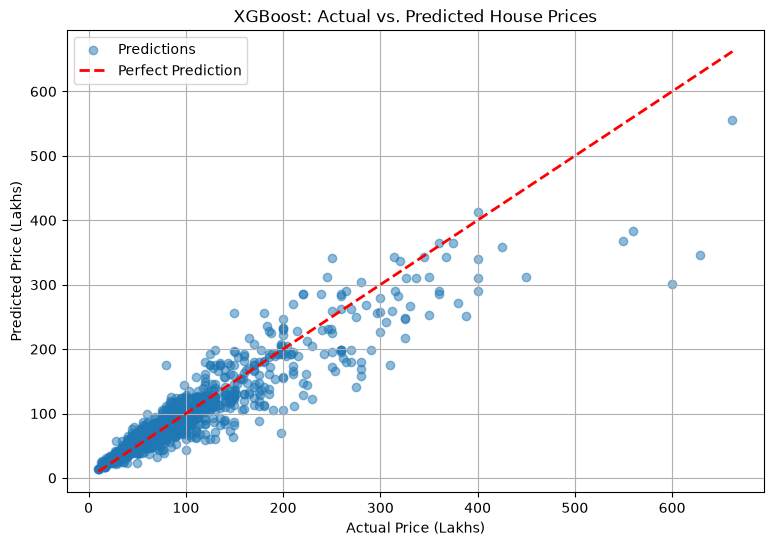

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Get the trained XGBoost model from the models dictionary
xgboost_model = models["XGBoost"]

# Predict on the test data; the model was trained on log-transformed prices
y_pred_log = xgboost_model.predict(X_test)
y_pred = np.expm1(y_pred_log)

# Evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("XGBoost Model Evaluation")
print(f"MAE: {mae:.2f} Lakhs")
print(f"RMSE: {rmse:.2f} Lakhs")
print(f"R² Score: {r2:.4f}")

# Actual vs. predicted comparison
comparison_df = pd.DataFrame({
    "Actual Price (Lakhs)": y_test.values,
    "Predicted Price (Lakhs)": y_pred,
    "Difference (Lakhs)": y_test.values - y_pred
})
display(comparison_df.round(2).head(10))

# Actual vs. predicted plot
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.figure(figsize=(9, 6))
plt.scatter(y_test, y_pred, alpha=0.5, label="Predictions")
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    linewidth=2,
    label="Perfect Prediction"
)
plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("XGBoost: Actual vs. Predicted House Prices")
plt.legend()
plt.grid(True)
plt.show()

In [8]:
# Round numerical columns to 2 decimal places

comparison_df_clean = comparison_df.round(2)

print("First 10 Sample Predictions:")
display(comparison_df_clean.head(10))

First 10 Sample Predictions:


,Actual Price (Lakhs),Predicted Price (Lakhs),Difference (Lakhs)
0,36.85,37.380001,-0.53
1,325.00,248.690002,76.31
2,66.00,59.919998,6.08
3,44.00,46.580002,-2.58
4,62.00,50.330002,11.67
5,71.00,76.589996,-5.59
6,120.00,117.839996,2.16
7,41.13,59.970001,-18.84
8,88.00,68.849998,19.15
9,110.00,125.089996,-15.09


In [10]:

import pandas as pd
import numpy as np

# 1. Custom test data
test_data = [
    {'location': 'Whitefield', 'total_sqft': 1170, 'bath': 2, 'balcony': 1, 'bhk': 2, 'actual_price': 52.0},
    {'location': 'Electronic City', 'total_sqft': 1500, 'bath': 3, 'balcony': 2, 'bhk': 3, 'actual_price': 72.5},
    {'location': 'Rajaji Nagar', 'total_sqft': 1200, 'bath': 2, 'balcony': 1, 'bhk': 2, 'actual_price': 145.0},
    {'location': 'Indiranagar', 'total_sqft': 2400, 'bath': 4, 'balcony': 3, 'bhk': 4, 'actual_price': 320.0},
    {'location': 'Sarjapur Road', 'total_sqft': 650, 'bath': 1, 'balcony': 1, 'bhk': 1, 'actual_price': 30.0},
    {'location': '1st Phase JP Nagar', 'total_sqft': 1875, 'bath': 3, 'balcony': 1, 'bhk': 3, 'actual_price': 167.0},
    {'location': 'Hebbal', 'total_sqft': 1600, 'bath': 2, 'balcony': 2, 'bhk': 3, 'actual_price': 95.0},
    {'location': 'Yelahanka', 'total_sqft': 1320, 'bath': 2, 'balcony': 2, 'bhk': 2, 'actual_price': 58.0},
    {'location': 'Koramangala', 'total_sqft': 2100, 'bath': 3, 'balcony': 2, 'bhk': 3, 'actual_price': 240.0},
    {'location': 'Marathahalli', 'total_sqft': 1100, 'bath': 2, 'balcony': 1, 'bhk': 2, 'actual_price': 65.0}
]

# 2. Predict prices using a robust version of predict_price_optimized that aligns feature names
results = []
best_xgb_model = models["XGBoost"]

# Fetch the expected feature columns directly from the model to avoid any casing issues
model_features = best_xgb_model.feature_names_in_

for sample in test_data:
    loc = sample['location'].lower().strip()

    # Build a DataFrame with 0s and ensure the column names match the model's feature names exactly
    input_data = pd.DataFrame(0, index=[0], columns=model_features)

    input_data.loc[0, 'total_sqft'] = sample['total_sqft']
    input_data.loc[0, 'bath'] = sample['bath']
    input_data.loc[0, 'balcony'] = sample['balcony']
    input_data.loc[0, 'bhk'] = sample['bhk']

    # Activate the lowercased location column if present
    if loc in input_data.columns:
        input_data.loc[0, loc] = 1

    pred_log = best_xgb_model.predict(input_data)[0]
    pred = max(0, float(np.expm1(pred_log)))

    results.append({
        'Location': sample['location'],
        'BHK': sample['bhk'],
        'Sqft': sample['total_sqft'],
        'Actual Price (Lakhs)': sample['actual_price'],
        'Predicted Price (Lakhs)': round(pred, 2),
        'Difference (Lakhs)': round(sample['actual_price'] - pred, 2)
    })

# 3. Display results
test_results_df = pd.DataFrame(results)
display(test_results_df)

,Location,BHK,Sqft,Actual Price (Lakhs),Predicted Price (Lakhs),Difference (Lakhs)
0,Whitefield,2,1170,52.0,59.55,-7.55
1,Electronic City,3,1500,72.5,86.93,-14.43
2,Rajaji Nagar,2,1200,145.0,64.87,80.13
3,Indiranagar,4,2400,320.0,175.88,144.12
4,Sarjapur Road,1,650,30.0,32.64,-2.64
5,1st Phase JP Nagar,3,1875,167.0,125.09,41.91
6,Hebbal,3,1600,95.0,92.85,2.15
7,Yelahanka,2,1320,58.0,70.58,-12.58
8,Koramangala,3,2100,240.0,137.27,102.73
9,Marathahalli,2,1100,65.0,53.55,11.45


Fitting 5 folds for each of 32 candidates, totalling 160 fits

--- Best XGBoost Parameters ---
{'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'subsample': 0.8}

--- Tuned XGBoost Evaluation ---
MAE: 14.59 Lakhs
RMSE: 25.88 Lakhs
R² Score: 0.8697


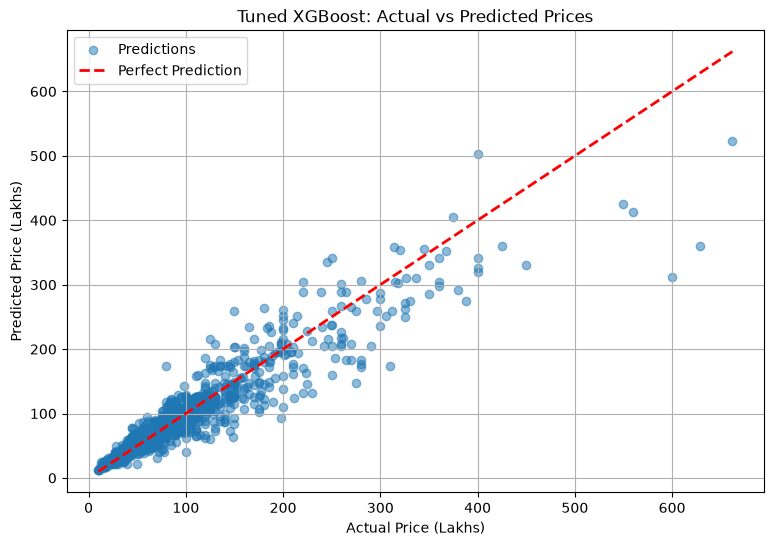


Indiranagar (2400 sqft, 4 BHK) - Predicted Price: 174.67 Lakhs


In [11]:

import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split, GridSearchCV, ShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ==========================================
# 1. PREPARE DATA
# ==========================================

# Use the same features prepared in Block 1
X = df11.drop('price', axis='columns').copy()

y = df11['price']

# Ensure the numerical features come first in the expected order
base_features = ['total_sqft', 'bath', 'balcony', 'bhk']
location_features = [col for col in X.columns if col not in base_features]
X = X[base_features + location_features]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=10
)

# Log-transform training prices
y_train_log = np.log1p(y_train)

# ==========================================
# 2. HYPERPARAMETER TUNING
# ==========================================

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

xgb_reg = xgb.XGBRegressor(
    objective='reg:squarederror',
    random_state=42,
    n_jobs=1
)

cv = ShuffleSplit(n_splits=5, test_size=0.2, random_state=0)

grid_search = GridSearchCV(
    estimator=xgb_reg,
    param_grid=param_grid,
    cv=cv,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train_log)

best_xgb_model = grid_search.best_estimator_

print("\n--- Best XGBoost Parameters ---")
print(grid_search.best_params_)

# ==========================================
# 3. EVALUATE THE TUNED MODEL
# ==========================================

# Predictions are on the log scale
y_pred_log = best_xgb_model.predict(X_test)

# Convert back to Lakhs
y_pred = np.expm1(y_pred_log)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n--- Tuned XGBoost Evaluation ---")
print(f"MAE: {mae:.2f} Lakhs")
print(f"RMSE: {rmse:.2f} Lakhs")
print(f"R² Score: {r2:.4f}")

# ==========================================
# 4. ACTUAL VS PREDICTED GRAPH
# ==========================================

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))
plt.scatter(y_test, y_pred, alpha=0.5, label='Predictions')

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    linewidth=2,
    label='Perfect Prediction'
)

plt.xlabel('Actual Price (Lakhs)')
plt.ylabel('Predicted Price (Lakhs)')
plt.title('Tuned XGBoost: Actual vs Predicted Prices')
plt.legend()
plt.grid(True)
plt.show()

# ==========================================
# 5. PREDICTION FUNCTION
# ==========================================

def predict_price_optimized(location, sqft, bath, bhk, balcony):
    location = location.lower().strip()

    # Match the exact feature columns used in training
    input_data = pd.DataFrame(0, index=[0], columns=X.columns)

    input_data.loc[0, 'total_sqft'] = sqft
    input_data.loc[0, 'bath'] = bath
    input_data.loc[0, 'balcony'] = balcony
    input_data.loc[0, 'bhk'] = bhk

    # Activate the location column if it exists
    if location in input_data.columns:
        input_data.loc[0, location] = 1

    pred_log = best_xgb_model.predict(input_data)[0]
    return max(0, float(np.expm1(pred_log)))

# ==========================================
# 6. TEST INDIRANAGAR
# ==========================================

indirangar_pred = predict_price_optimized(
    'Indiranagar', 2400, 4, 4, 3
)

print(
    f"\nIndiranagar (2400 sqft, 4 BHK) - "
    f"Predicted Price: {indirangar_pred:.2f} Lakhs"
)

In [12]:

import json
import joblib

# Save the tuned XGBoost model in native JSON format
best_xgb_model.save_model("best_xgb_model.json")

# Save the exact feature-column order
columns = {"data_columns": list(X.columns)}

with open("columns.json", "w") as f:
    json.dump(columns, f)

print("Tuned XGBoost model and feature columns saved successfully.")

Tuned XGBoost model and feature columns saved successfully.


In [13]:
import json

columns = {"data_columns": list(X.columns)}

with open("columns.json", "w") as f:
    json.dump(columns, f)

print("columns.json created successfully!")

columns.json created successfully!


In [15]:

import json
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

metrics = {}

for name, model in models.items():
    pred_log = model.predict(X_test)
    pred_price = np.expm1(pred_log)

    metrics[name] = {
        "MAE": float(mean_absolute_error(y_test, pred_price)),
        "RMSE": float(np.sqrt(mean_squared_error(y_test, pred_price))),
        "R2 Score": float(r2_score(y_test, pred_price))
    }

with open("model_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)



In [16]:

import joblib

# Keep only the first three models
other_models = {
    name: model
    for name, model in models.items()
    if name != "XGBoost"
}

# Create a separate file
joblib.dump(other_models, "other_models.pkl")

print("New file created successfully!")
print("Models saved:", list(other_models.keys()))

New file created successfully!
Models saved: ['Linear Regression', 'Decision Tree', 'Random Forest']


TEST DATA

In [ ]:
import pandas as pd
import numpy as np

# 1. Align the full test set features with the tuned model's requirements
expected_features = list(best_xgb_model.feature_names_in_)
col_mapping = {str(col).lower(): col for col in X_test.columns}
aligned_cols = [col_mapping[str(feature).lower()] for feature in expected_features if str(feature).lower() in col_mapping]

X_test_eval = X_test[aligned_cols].copy()
X_test_eval.columns = expected_features

# 2. Get predictions using the tuned XGBoost model
y_pred_log = best_xgb_model.predict(X_test_eval)
y_pred_actual = np.expm1(y_pred_log)

# 3. Reconstruct human-readable features (reversing one-hot encoding for location)
original_locations = []
for idx, row in X_test.iterrows():
    # Find the one-hot encoded column that is True
    location_dummies = row.drop(['total_sqft', 'bath', 'balcony', 'bhk'])
    active_locs = location_dummies[location_dummies == True].index.tolist()
    if active_locs:
        original_locations.append(active_locs[0])
    else:
        original_locations.append('other')

# 4. Create the final full test info DataFrame
full_test_info_df = pd.DataFrame({
    'Location': original_locations,
    'Total Sqft': X_test_eval['total_sqft'].values,
    'BHK': X_test_eval['bhk'].values,
    'Bathrooms': X_test_eval['bath'].values,
    'Balcony': X_test_eval['balcony'].values,
    'Actual Price (Lakhs)': y_test.values,
    'Predicted Price (Lakhs)': np.round(y_pred_actual, 2),
    'Difference / Error (Lakhs)': np.round(y_test.values - y_pred_actual, 2)
})

# Save the full results to a CSV file
full_test_info_df.to_csv('full_test_predictions.csv', index=False)
print(f"Created 'full_test_predictions.csv' containing all {len(full_test_info_df)} test rows.\n")

# Display the top 50 rows of this dataset
pd.set_option('display.max_rows', 100)
display(full_test_info_df.head(50))

Created 'full_test_predictions.csv' containing all 1390 test rows.



,Location,Total Sqft,BHK,Bathrooms,Balcony,Actual Price (Lakhs),Predicted Price (Lakhs),Difference / Error (Lakhs)
0,Yeshwanthpur,670.00,1,1.0,1.0,36.85,36.830002,0.02
1,other,2900.00,3,3.0,2.0,325.00,252.119995,72.88
2,Bannerghatta Road,1170.00,3,2.0,1.0,66.00,60.250000,5.75
3,Haralur Road,1027.00,2,2.0,2.0,44.00,44.889999,-0.89
4,Battarahalli,1071.00,2,2.0,1.0,62.00,46.369999,15.63
5,Electronic City,1360.00,3,2.0,1.0,71.00,76.809998,-5.81
6,other,1200.00,4,4.0,0.0,120.00,120.040001,-0.04
7,Banashankari,1175.00,2,2.0,1.0,41.13,60.439999,-19.31
8,6th Phase JP Nagar,1280.00,2,2.0,1.0,88.00,72.089996,15.91
9,Hoodi,1925.00,3,3.0,3.0,110.00,123.849998,-13.85


In [22]:
import numpy as np
import json

# 1. Ensure y_test is in normal Lakhs
y_test_array = np.array(y_test, dtype=float)

# If max value is under 15, it's log-transformed; convert to lakhs. Otherwise keep as-is.
if y_test_array.max() < 15:
    y_test_lakhs = np.expm1(y_test_array)
else:
    y_test_lakhs = y_test_array

# Save y_test.npy (overwrite)
np.save("y_test.npy", y_test_lakhs)
print("Max value in y_test.npy:", np.max(y_test_lakhs))  # Should be a reasonable price like 300 or 500


# 2. Get predictions for each model safely
predictions_dict = {}

# Use your models dictionary (or list your models manually)
for model_name, model_obj in models_dict.items():
    preds = model_obj.predict(X_test)
    
    # Check if predictions are log-scale or standard
    if np.max(preds) < 15:
        preds_lakhs = np.expm1(preds)
    else:
        preds_lakhs = preds
        
    # Convert to standard Python float list
    predictions_dict[model_name] = [float(p) for p in preds_lakhs]

# Save test_predictions.json (overwrite)
with open("test_predictions.json", "w") as f:
    json.dump(predictions_dict, f)

print("✅ Files successfully updated and overwritten!")

Max value in y_test.npy: 662.0
✅ Files successfully updated and overwritten!
